# 📊 Phân tích & Đánh giá Branch Coverage của Unit Test do LLM sinh
### So sánh 6 mô hình LLM trên bộ dữ liệu song ngữ Java & Python


---

**Bối cảnh:** Notebook này xử lý và phân tích kết quả thực nghiệm mà nhóm đã tự thiết kế: dùng 6 LLM khác nhau để sinh unit test tự động cho một tập hàm Java/Python đã được kiểm chứng (verified), sau đó đo **branch coverage** thực tế bằng JaCoCo (Java) / coverage.py (Python).

**6 mô hình được đánh giá:**
| Model | Vai trò dự kiến |
|---|---|
| Gemini-3.7-Flash | Model thương mại, tier khá |
| Gemini-3.5-Flash-Lite | Model thương mại, tier nhẹ |
| Gemma-4-26B-A4B-IT | Model mở, kích thước trung bình |
| Gemma-4-31B-IT | Model mở, kích thước trung bình-lớn |
| GPT-OSS-120B | Model mở, kích thước lớn |
| GPT-5.6-Luna | Model thương mại cao cấp |

**Dữ liệu:** 646 hàm × 6 model = **3,876 quan sát** (327 hàm Java + 319 hàm Python, độ phức tạp cyclomatic — `cc` — phân bố gần như đồng nhất giữa 2 ngôn ngữ, sẽ được kiểm chứng lại ở mục 2).

**Mục tiêu của notebook:**
1. Nạp và kiểm tra tính toàn vẹn dữ liệu (data validation) — vì đây là dữ liệu tự tổng hợp từ nhiều file CSV rời rạc.
2. Thống kê mô tả tổng quan theo model / ngôn ngữ.
3. Trực quan hóa nhiều góc nhìn (tỉ lệ thành công, phân phối coverage, ảnh hưởng độ phức tạp, số lượng test case...).
4. Kiểm định thống kê để các kết luận có căn cứ định lượng khi bảo vệ trước giảng viên.
5. Gợi ý các "góc khai thác" (insight angles) có thể đưa vào báo cáo/slide, và một khung outline trình bày.


## Mục lục
1. [Nạp dữ liệu](#1)
2. [Kiểm tra tính toàn vẹn dữ liệu](#2)
3. [Tiền xử lý & tạo biến phụ trợ](#3)
4. [Thống kê mô tả tổng quan](#4)
5. [Trực quan hóa](#5)
6. [Kiểm định thống kê](#6)
7. [Phân tích sâu — góc khai thác cho báo cáo](#7)
8. [Xuất bảng & biểu đồ](#8)
9. [Gợi ý outline trình bày báo cáo](#9)


## 0. Cài đặt thư viện

In [ ]:
# Các thư viện dưới đây đều có sẵn trên Google Colab, không cần cài thêm.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import itertools
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.facecolor'] = 'white'
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)

MODEL_ORDER = ['Gemini-3.7-Flash', 'GPT-5.6-Luna', 'Gemma-4-31B-IT',
               'Gemma-4-26B-A4B-IT', 'Gemini-3.5-Flash-Lite', 'GPT-OSS-120B']
PALETTE = dict(zip(MODEL_ORDER, sns.color_palette('tab10', len(MODEL_ORDER))))
LANG_PALETTE = {'java': '#E76F51', 'python': '#2A9D8F'}

import os
os.makedirs('figures', exist_ok=True)

def save(fig, name):
    fig.savefig(f'figures/{name}.png', dpi=180, bbox_inches='tight')


<a id="1"></a>
## 1. Nạp dữ liệu

Notebook này đọc trực tiếp sheet **`Raw_Data`** trong file `master_result.xlsx` — đây là bản dữ liệu đã được hợp nhất từ 8 file CSV kết quả (mỗi model một file, một số file gộp chung Java+Python được tách theo tiền tố id) + đã gán nhãn model rõ ràng.

> ⚠️ Notebook **không** dùng lại các file `master_results.csv` nằm rời trong từng thư mục kết quả gốc, vì khi kiểm tra thủ công, một vài file trong số đó bị **lẫn dữ liệu của lần chạy python trước** (cột `model` xuất hiện `gemini_gemini-3.5-flash-lite_python` trong cả các thư mục không liên quan). File `master_result.xlsx` là bản đã được dọn sạch vấn đề này — nhưng vẫn nên đọc kỹ khối README bên dưới trước khi tin tưởng hoàn toàn.

Chạy cell bên dưới và chọn file `master_result.xlsx` từ máy khi được yêu cầu upload.


In [ ]:
from google.colab import files
import io

uploaded = files.upload()  # chọn master_result.xlsx
fname = list(uploaded.keys())[0]
xls = pd.ExcelFile(io.BytesIO(uploaded[fname]))
print('Các sheet có trong file:', xls.sheet_names)

df = pd.read_excel(xls, sheet_name='Raw_Data')
readme = pd.read_excel(xls, sheet_name='README', header=None)
print(df.shape)
df.head()


Saving master_result.xlsx to master_result.xlsx
Các sheet có trong file: ['README', 'Summary_by_Model', 'Summary_by_Model_Language', 'Raw_Data']
(3876, 8)


,id,language,model,cc,branch_coverage,status,status_detail,testcase_count
0,java_final_0001,java,Gemma-4-26B-A4B-IT,7,100.00,ok,ok,12
1,java_final_0002,java,Gemma-4-26B-A4B-IT,7,75.93,test_failed,test_failed,7
2,java_final_0003,java,Gemma-4-26B-A4B-IT,7,71.43,test_failed,test_failed,8
3,java_final_0004,java,Gemma-4-26B-A4B-IT,7,100.00,test_failed,test_failed,10
4,java_final_0005,java,Gemma-4-26B-A4B-IT,7,100.00,ok,ok,6


In [ ]:
# In lại toàn bộ ghi chú README gốc — LUÔN đọc kỹ mục này trước khi diễn giải kết quả,
# vì nó ghi rõ những chỗ dữ liệu được suy luận/gán thủ công (không phải log gốc 100%).
for _, row in readme.iterrows():
    a, b = row[0], row[1]
    if pd.notna(a):
        print(f"- {a}" + (f": {b}" if pd.notna(b) else ""))


- Tổng hợp kết quả unit test coverage của 6 LLM
- Nguồn dữ liệu: 8 file CSV + 1 file XLSX trong master_result.zip
- Số hàm Java: 327 (functions_java_VERIFIED.jsonl)
- Số hàm Python: 319 (functions_python_VERIFIED.jsonl)
- 6 model: Gemini-3.7-Flash, Gemini-3.5-Flash-Lite, Gemma-4-26B-A4B-IT, Gemma-4-31B-IT, GPT-OSS-120B, GPT-5.6-Luna
- LƯU Ý QUAN TRỌNG (cần bạn xác nhận):
- - File 'Ket_Qua_Nghien_Cuu_Coverage_python.xlsx' không có tên model trong dữ liệu gốc.
-   Tôi đã gán tạm cho model 'GPT-5.6-Luna' (phần Python) vì đây là model DUY NHẤT
-   còn thiếu dữ liệu Python trong bộ 6 model. Vui lòng xác nhận lại điều này.
- - Với 3 file (Gemma-4-26B-A4B-IT, Gemma-4-31B-IT, GPT-OSS-120B), dữ liệu Java và Python
-   nằm chung 1 file gốc, được tôi tách theo tiền tố id (java_final_ / py_final_).
- Các sheet
- Summary_by_Model: Tổng hợp theo từng model (gộp cả Java + Python)
- Summary_by_Model_Language: Tổng hợp theo từng model x ngôn ngữ, đầy đủ các loại status
- Raw_Data: 3,876 dòng dữ liệu gố

<a id="2"></a>
## 2. Kiểm tra tính toàn vẹn dữ liệu

Vì dữ liệu được ghép từ nhiều nguồn (nhiều lần chạy pipeline, nhiều máy), bước validate là **bắt buộc** trước khi phân tích — giảng viên rất hay hỏi "làm sao em biết dữ liệu đúng?". Các câu hỏi cần trả lời:

- Có đủ 6 model × 646 hàm (327 Java + 319 Python) không?
- Có hàng trùng lặp không?
- Có giá trị thiếu (NaN) không, rơi vào trường hợp nào?
- Phân bố độ phức tạp (cc) giữa 2 ngôn ngữ có thực sự "khá đều" như giả định ban đầu không?


In [ ]:
print("Tổng số quan sát:", len(df))
print("\nSố quan sát theo model:")
print(df['model'].value_counts())

print("\nSố quan sát theo model x ngôn ngữ (kỳ vọng: mỗi ô = 327 java / 319 python):")
pivot_check = df.groupby(['model', 'language']).size().unstack()
display(pivot_check)

print("\nGiá trị thiếu theo cột:")
print(df.isna().sum())

print("\nSố hàng trùng lặp (id, model):", df.duplicated(subset=['id', 'model']).sum())

print("\nCác dòng có branch_coverage bị thiếu (thường do không sinh được test):")
display(df[df['branch_coverage'].isna()])


Tổng số quan sát: 3876

Số quan sát theo model:
model
Gemma-4-26B-A4B-IT       646
Gemma-4-31B-IT           646
Gemini-3.7-Flash         646
GPT-OSS-120B             646
Gemini-3.5-Flash-Lite    646
GPT-5.6-Luna             646
Name: count, dtype: int64

Số quan sát theo model x ngôn ngữ (kỳ vọng: mỗi ô = 327 java / 319 python):


language,java,python
model,,
GPT-5.6-Luna,327,319
GPT-OSS-120B,327,319
Gemini-3.5-Flash-Lite,327,319
Gemini-3.7-Flash,327,319
Gemma-4-26B-A4B-IT,327,319
Gemma-4-31B-IT,327,319



Giá trị thiếu theo cột:
id                 0
language           0
model              0
cc                 0
branch_coverage    2
status             0
status_detail      0
testcase_count     0
dtype: int64

Số hàng trùng lặp (id, model): 0

Các dòng có branch_coverage bị thiếu (thường do không sinh được test):


,id,language,model,cc,branch_coverage,status,status_detail,testcase_count
1519,java_final_0259,java,Gemini-3.7-Flash,12,NaN,no_test_generated,no_test_generated,0
1572,java_final_0327,java,Gemini-3.7-Flash,14,NaN,no_test_generated,no_test_generated,0


,count,mean,std,min,25%,50%,75%,max
language,,,,,,,,
java,327.0,10.021407,3.367496,5.0,7.0,10.0,13.0,15.0
python,319.0,10.100313,2.974097,5.0,7.0,10.0,12.0,15.0


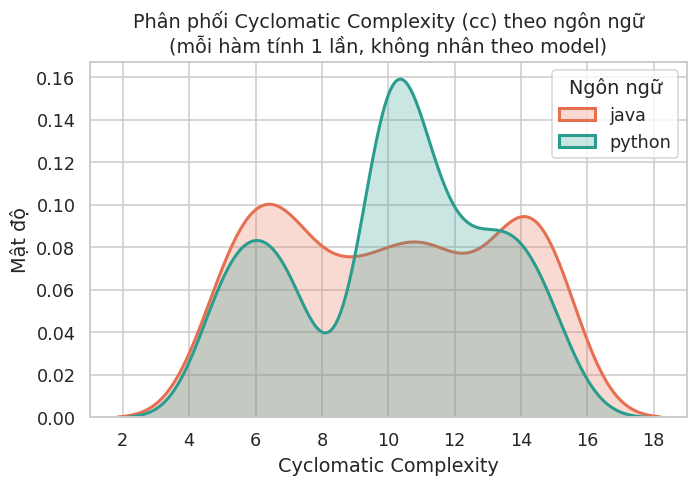

→ Nếu mean/median/std giữa 2 ngôn ngữ gần nhau: khẳng định được thiết kế dataset đã cân bằng độ khó,
  nên mọi khác biệt coverage giữa Java/Python sau này khó thể đổ lỗi cho 'python đơn giản hơn'.


In [ ]:
# Kiểm chứng claim "phân bố CC khá đều giữa 2 ngôn ngữ"
cc_by_lang = df.drop_duplicates(subset=['id', 'language']).groupby('language')['cc'].describe()
display(cc_by_lang)

fig, ax = plt.subplots(figsize=(7, 4.2))
for lang, color in LANG_PALETTE.items():
    sub = df[df['language'] == lang].drop_duplicates(subset='id')
    sns.kdeplot(sub['cc'], ax=ax, label=lang, color=color, fill=True, alpha=0.25, linewidth=2)
ax.set_title('Phân phối Cyclomatic Complexity (cc) theo ngôn ngữ\n(mỗi hàm tính 1 lần, không nhân theo model)')
ax.set_xlabel('Cyclomatic Complexity'); ax.set_ylabel('Mật độ')
ax.legend(title='Ngôn ngữ')
save(fig, '01_cc_distribution_by_language')
plt.show()

print("→ Nếu mean/median/std giữa 2 ngôn ngữ gần nhau: khẳng định được thiết kế dataset đã cân bằng độ khó,")
print("  nên mọi khác biệt coverage giữa Java/Python sau này khó thể đổ lỗi cho 'python đơn giản hơn'.")


In [ ]:
# Một phát hiện quan trọng cần nêu rõ trong báo cáo: nhãn trạng thái LỖI không tương xứng 1-1 giữa 2 ngôn ngữ
status_by_lang = pd.crosstab(df['language'], df['status'])
display(status_by_lang)

note_lines = [
    "NHẬN XÉT QUAN TRỌNG (nên đưa vào phần 'giới hạn dữ liệu' của báo cáo):",
    "- Java dùng nhãn 'compile_error' (lỗi biên dịch) — Python KHÔNG bao giờ có nhãn này (đúng bản chất,",
    "  Python không có bước compile).",
    "- Python dùng nhãn 'coverage_error' cho các trường hợp lỗi tương tự (import lỗi, syntax lỗi khi chạy) —",
    "  Java hầu như không dùng nhãn này.",
    "=> Hai nhãn 'compile_error' (Java) và 'coverage_error' (Python) về BẢN CHẤT đóng vai trò tương đương nhau",
    "   ('mã không chạy được'), chỉ khác tên do công cụ đo khác nhau (JaCoCo vs coverage.py).",
    "   Khi so sánh 'tỉ lệ lỗi build' giữa 2 ngôn ngữ, cần GỘP 2 nhãn này lại thành 1 nhóm 'build_error'",
    "   để so sánh công bằng — xem mục 3 bên dưới.",
]
print('\\n'.join(note_lines))


status,compile_error,coverage_error,error,no_data,no_test_generated,ok,test_failed,timeout
language,,,,,,,,
java,236,0,14,3,2,1219,481,7
python,0,202,0,0,0,887,819,6


NHẬN XÉT QUAN TRỌNG (nên đưa vào phần 'giới hạn dữ liệu' của báo cáo):\n- Java dùng nhãn 'compile_error' (lỗi biên dịch) — Python KHÔNG bao giờ có nhãn này (đúng bản chất,\n  Python không có bước compile).\n- Python dùng nhãn 'coverage_error' cho các trường hợp lỗi tương tự (import lỗi, syntax lỗi khi chạy) —\n  Java hầu như không dùng nhãn này.\n=> Hai nhãn 'compile_error' (Java) và 'coverage_error' (Python) về BẢN CHẤT đóng vai trò tương đương nhau\n   ('mã không chạy được'), chỉ khác tên do công cụ đo khác nhau (JaCoCo vs coverage.py).\n   Khi so sánh 'tỉ lệ lỗi build' giữa 2 ngôn ngữ, cần GỘP 2 nhãn này lại thành 1 nhóm 'build_error'\n   để so sánh công bằng — xem mục 3 bên dưới.


<a id="3"></a>
## 3. Tiền xử lý & tạo biến phụ trợ

- `build_error`: gộp `compile_error` (Java) + `coverage_error` (Python) thành một nhóm lỗi "mã không build/chạy được" để so sánh công bằng giữa 2 ngôn ngữ.
- `complexity_level`: chia `cc` thành 3 mức Thấp/Trung bình/Cao theo tam phân vị (qcut) — dùng để phân tích "coverage cliff" (coverage sụt giảm ra sao khi hàm phức tạp hơn).
- `coverage_efficiency`: branch_coverage / testcase_count (chỉ tính khi status = ok) — đo "1 test case tạo ra bao nhiêu % coverage", phản ánh chất lượng test thay vì chỉ số lượng.


In [ ]:
df['build_error'] = df['status'].isin(['compile_error', 'coverage_error'])

df['complexity_level'] = pd.qcut(df['cc'], q=3, labels=['Thấp', 'Trung bình', 'Cao'])
print("Ngưỡng chia mức độ phức tạp (theo tam phân vị của cc):")
display(df.groupby('complexity_level', observed=True)['cc'].agg(['min', 'max', 'count']))

df['coverage_efficiency'] = np.where(
    (df['status'] == 'ok') & (df['testcase_count'] > 0),
    df['branch_coverage'] / df['testcase_count'],
    np.nan
)

df_ok = df[df['status'] == 'ok'].copy()
print(f"\nSố quan sát status=ok: {len(df_ok)} / {len(df)} ({len(df_ok)/len(df)*100:.1f}%)")
print("→ Mọi thống kê 'Avg Branch Coverage' phía sau chỉ tính trên tập con df_ok này,")
print("  vì coverage=0 của các hàm lỗi biên dịch không phản ánh chất lượng test, mà phản ánh lỗi hạ tầng/model sinh sai cú pháp.")


Ngưỡng chia mức độ phức tạp (theo tam phân vị của cc):


,min,max,count
complexity_level,,,
Thấp,5,9,1440
Trung bình,10,12,1380
Cao,13,15,1056



Số quan sát status=ok: 2106 / 3876 (54.3%)
→ Mọi thống kê 'Avg Branch Coverage' phía sau chỉ tính trên tập con df_ok này,
  vì coverage=0 của các hàm lỗi biên dịch không phản ánh chất lượng test, mà phản ánh lỗi hạ tầng/model sinh sai cú pháp.


<a id="4"></a>
## 4. Thống kê mô tả tổng quan


In [ ]:
def summarize(g):
    total = len(g)
    ok = (g['status'] == 'ok').sum()
    return pd.Series({
        'Total': total,
        'Ok_Rate_%': round(ok / total * 100, 2),
        'Avg_Coverage_OK_%': round(g.loc[g['status'] == 'ok', 'branch_coverage'].mean(), 2),
        'Median_Coverage_OK_%': round(g.loc[g['status'] == 'ok', 'branch_coverage'].median(), 2),
        'Avg_Testcase_Count': round(g['testcase_count'].mean(), 2),
        'Build_Error_%': round(g['build_error'].sum() / total * 100, 2),
        'Test_Failed_%': round((g['status'] == 'test_failed').sum() / total * 100, 2),
    })

summary_model = df.groupby('model').apply(summarize, include_groups=False)
summary_model = summary_model.loc[MODEL_ORDER].sort_values('Ok_Rate_%', ascending=False)
print("=== Bảng tổng hợp theo MODEL (gộp Java + Python) ===")
display(summary_model.style.background_gradient(subset=['Ok_Rate_%', 'Avg_Coverage_OK_%'], cmap='Greens'))


=== Bảng tổng hợp theo MODEL (gộp Java + Python) ===


,Total,Ok_Rate_%,Avg_Coverage_OK_%,Median_Coverage_OK_%,Avg_Testcase_Count,Build_Error_%,Test_Failed_%
model,,,,,,,
Gemini-3.7-Flash,646.000000,79.880000,90.390000,100.000000,11.840000,7.120000,10.220000
GPT-5.6-Luna,646.000000,69.810000,86.410000,100.000000,12.140000,3.250000,26.780000
Gemma-4-31B-IT,646.000000,54.800000,95.760000,100.000000,9.920000,6.970000,37.620000
Gemini-3.5-Flash-Lite,646.000000,45.360000,94.410000,100.000000,7.590000,17.030000,37.000000
Gemma-4-26B-A4B-IT,646.000000,44.890000,94.850000,100.000000,9.820000,13.930000,40.710000
GPT-OSS-120B,646.000000,31.270000,94.450000,100.000000,8.580000,19.500000,48.920000


In [ ]:
summary_model_lang = df.groupby(['model', 'language']).apply(summarize, include_groups=False)
print("=== Bảng tổng hợp theo MODEL x NGÔN NGỮ ===")
display(summary_model_lang.style.background_gradient(subset=['Ok_Rate_%', 'Avg_Coverage_OK_%'], cmap='Greens'))


=== Bảng tổng hợp theo MODEL x NGÔN NGỮ ===


<a id="5"></a>
## 5. Trực quan hóa

### 5.1 Tỉ lệ thành công (Ok Rate) theo model
`Ok Rate` = % số hàm mà bộ test sinh ra biên dịch được, chạy được, và pass — chỉ số "chất lượng đầu ra thô" trước khi xét coverage.


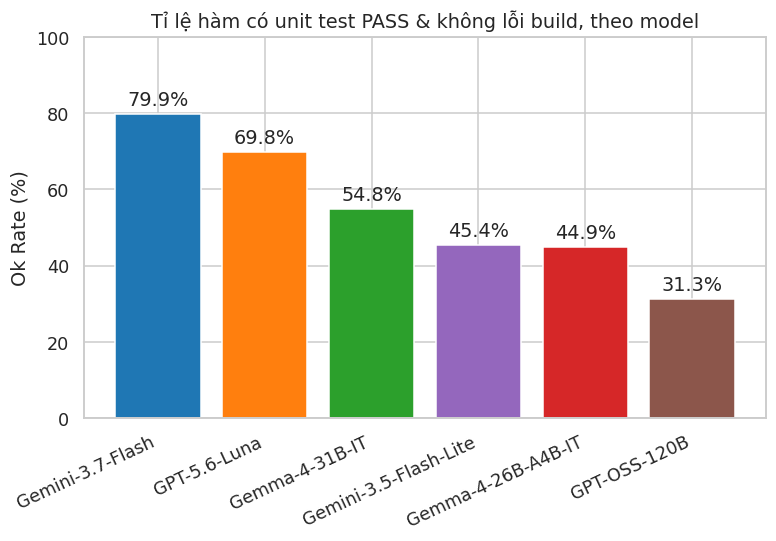

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
order = summary_model.index
bars = ax.bar(order, summary_model['Ok_Rate_%'], color=[PALETTE[m] for m in order])
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_ylabel('Ok Rate (%)')
ax.set_title('Tỉ lệ hàm có unit test PASS & không lỗi build, theo model')
ax.set_ylim(0, 100)
plt.xticks(rotation=25, ha='right')
save(fig, '02_ok_rate_by_model')
plt.show()


### 5.2 Ok Rate theo Model × Ngôn ngữ

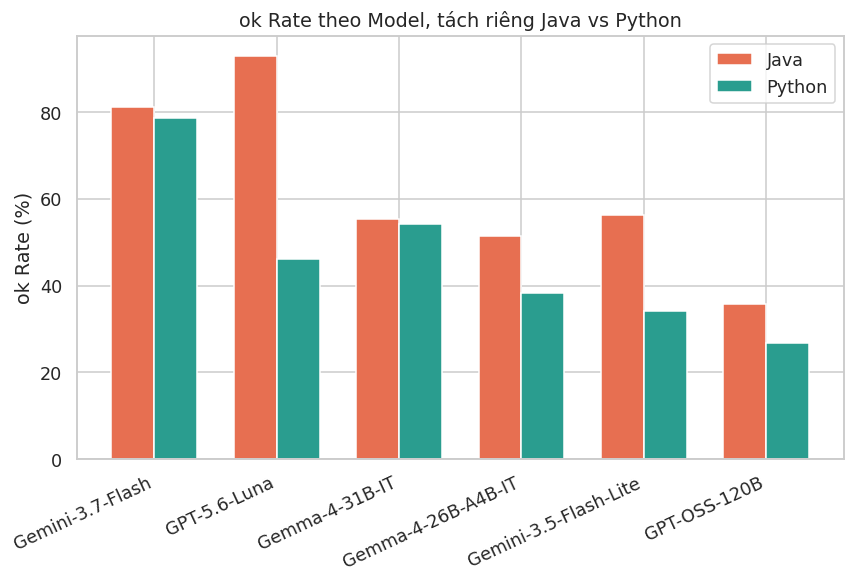

In [28]:
pivot_ok = df.groupby(['model', 'language']).apply(
    lambda g: (g['status'] == 'ok').sum() / len(g) * 100, include_groups=False
).unstack().loc[MODEL_ORDER]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(pivot_ok)); width = 0.35
ax.bar(x - width/2, pivot_ok['java'], width, label='Java', color=LANG_PALETTE['java'])
ax.bar(x + width/2, pivot_ok['python'], width, label='Python', color=LANG_PALETTE['python'])
ax.set_xticks(x); ax.set_xticklabels(pivot_ok.index, rotation=25, ha='right')
ax.set_ylabel('ok Rate (%)')
ax.set_title('ok Rate theo Model, tách riêng Java vs Python')
ax.legend()
save(fig, '03_ok_rate_by_model_language')
plt.show()


### 5.3 Phân phối trạng thái đầy đủ (status breakdown) theo model
Nhìn sâu hơn "ok rate": trong phần KHÔNG ok, model thất bại chủ yếu vì **build lỗi** (model sinh sai cú pháp) hay vì **test logic sai** (`test_failed` — model hiểu sai hành vi hàm)? Đây là hai loại lỗi có ý nghĩa rất khác nhau khi đánh giá năng lực model.


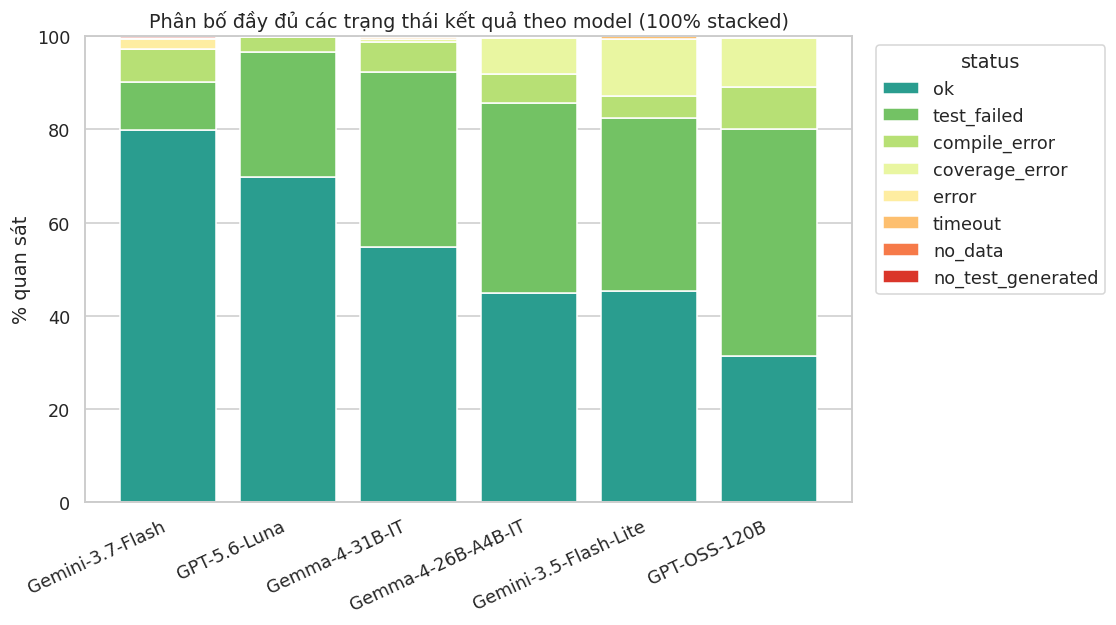

In [ ]:
status_order = ['ok', 'test_failed', 'compile_error', 'coverage_error', 'error', 'timeout', 'no_data', 'no_test_generated']
status_colors = dict(zip(status_order, sns.color_palette('RdYlGn_r', len(status_order))))
status_colors['ok'] = '#2A9D8F'

pct = pd.crosstab(df['model'], df['status'], normalize='index')[
    [c for c in status_order if c in df['status'].unique()]
].loc[MODEL_ORDER] * 100

fig, ax = plt.subplots(figsize=(9, 5.5))
bottom = np.zeros(len(pct))
for status in pct.columns:
    ax.bar(pct.index, pct[status], bottom=bottom, label=status, color=status_colors.get(status))
    bottom += pct[status].values
ax.set_ylabel('% quan sát')
ax.set_title('Phân bố đầy đủ các trạng thái kết quả theo model (100% stacked)')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='status')
plt.xticks(rotation=25, ha='right')
save(fig, '04_status_breakdown_stacked')
plt.show()


### 5.4 Phân phối Branch Coverage (chỉ tính các hàm `ok`) theo model


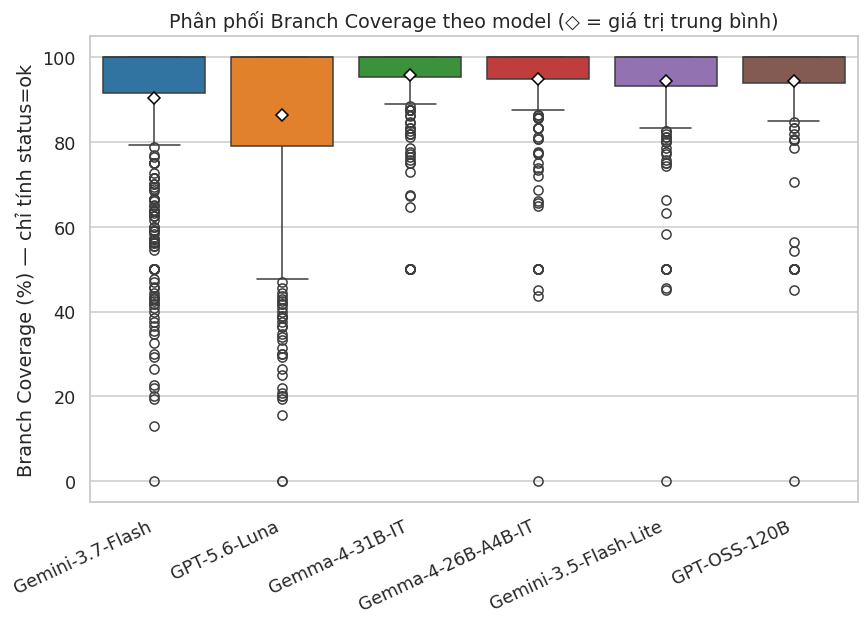

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=df_ok, x='model', y='branch_coverage', order=MODEL_ORDER,
            palette=PALETTE, ax=ax, showmeans=True,
            meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black', 'markersize': 6})
ax.set_ylabel('Branch Coverage (%) — chỉ tính status=ok')
ax.set_xlabel('')
ax.set_title('Phân phối Branch Coverage theo model (◇ = giá trị trung bình)')
plt.xticks(rotation=25, ha='right')
save(fig, '05_coverage_boxplot_by_model')
plt.show()


### 5.5 Branch Coverage theo Model, tách theo ngôn ngữ (violin)

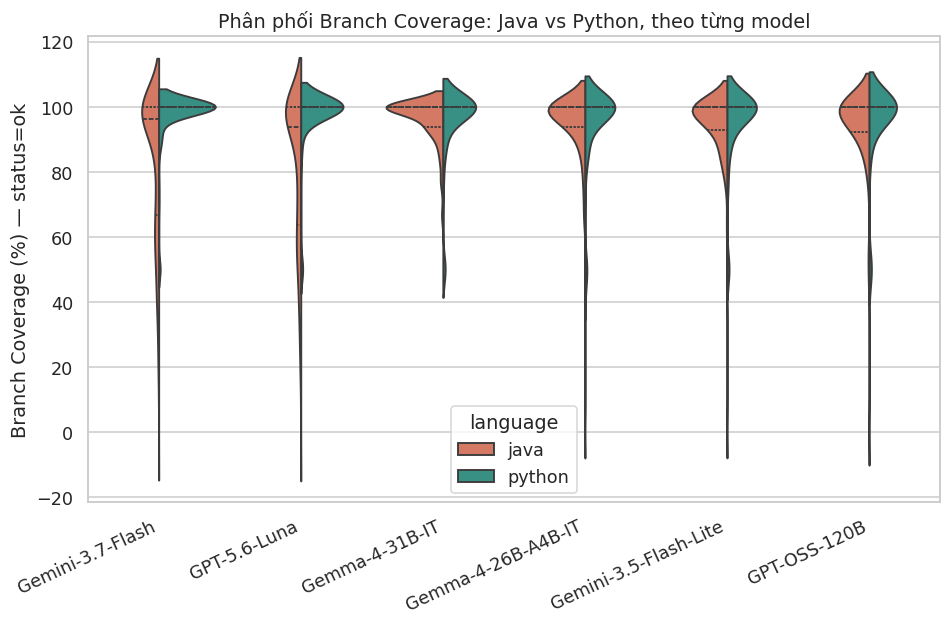

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.violinplot(data=df_ok, x='model', y='branch_coverage', hue='language', order=MODEL_ORDER,
               palette=LANG_PALETTE, split=True, ax=ax, inner='quartile')
ax.set_ylabel('Branch Coverage (%) — status=ok')
ax.set_xlabel('')
ax.set_title('Phân phối Branch Coverage: Java vs Python, theo từng model')
plt.xticks(rotation=25, ha='right')
save(fig, '06_coverage_violin_by_model_language')
plt.show()


### 5.6 "Coverage cliff": Coverage trung bình sụt giảm ra sao khi độ phức tạp tăng?
Giả thuyết cần kiểm chứng: **hàm càng phức tạp (cc cao), LLM càng khó sinh test bao phủ đủ nhánh.**


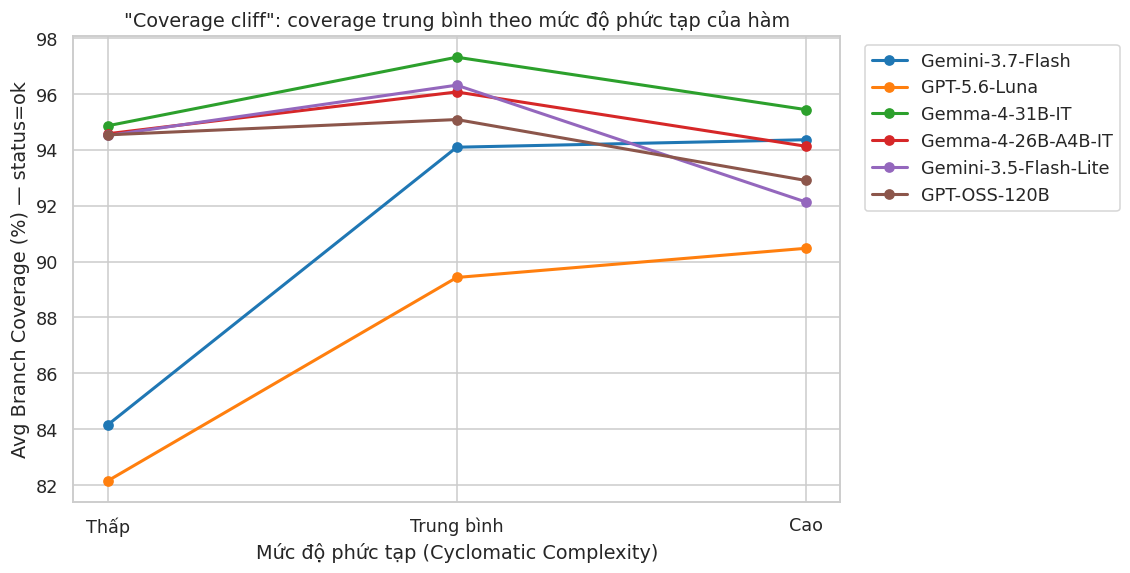

complexity_level,Thấp,Trung bình,Cao
model,,,
Gemini-3.7-Flash,84.161429,94.091771,94.359172
GPT-5.6-Luna,82.155123,89.429265,90.472411
Gemma-4-31B-IT,94.860723,97.313571,95.439342
Gemma-4-26B-A4B-IT,94.574483,96.069324,94.127887
Gemini-3.5-Flash-Lite,94.511707,96.312576,92.134762
GPT-OSS-120B,94.534444,95.082143,92.903793


In [ ]:
cliff = df_ok.groupby(['model', 'complexity_level'], observed=True)['branch_coverage'].mean().unstack()
cliff = cliff.loc[MODEL_ORDER]

fig, ax = plt.subplots(figsize=(9, 5.5))
for model in MODEL_ORDER:
    ax.plot(cliff.columns, cliff.loc[model], marker='o', label=model, color=PALETTE[model], linewidth=2)
ax.set_ylabel('Avg Branch Coverage (%) — status=ok')
ax.set_xlabel('Mức độ phức tạp (Cyclomatic Complexity)')
ax.set_title('"Coverage cliff": coverage trung bình theo mức độ phức tạp của hàm')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
save(fig, '07_coverage_cliff_by_complexity')
plt.show()
display(cliff.style.background_gradient(cmap='RdYlGn', axis=None))


### 5.7 Số lượng test case sinh ra vs Coverage đạt được — số lượng có tỉ lệ thuận với chất lượng không?


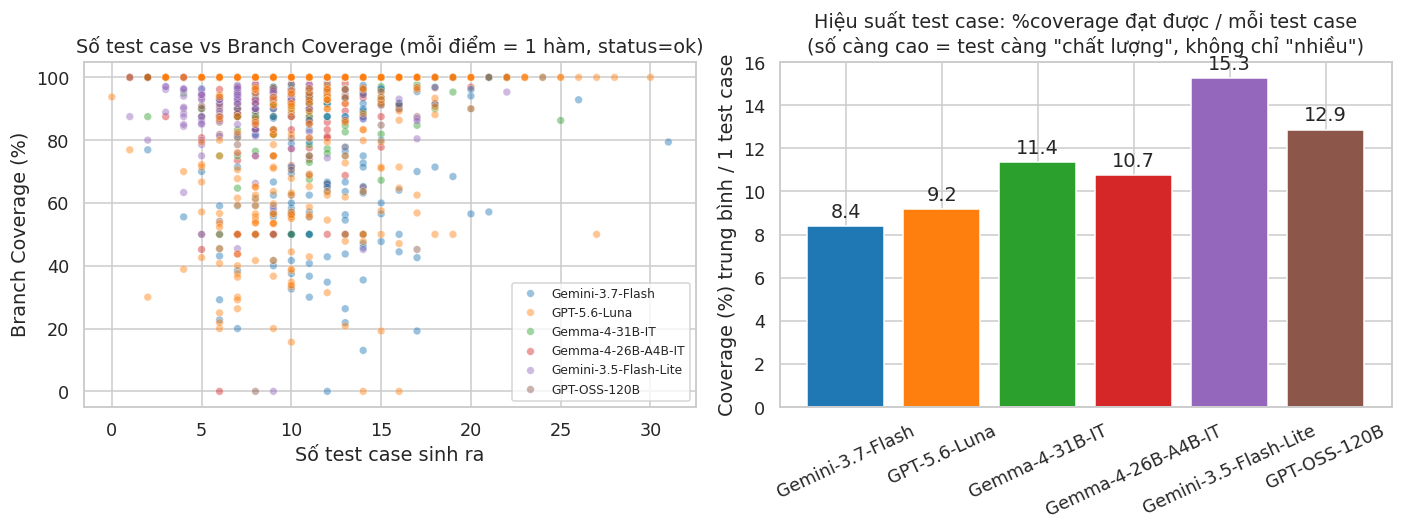

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=df_ok, x='testcase_count', y='branch_coverage', hue='model',
                 hue_order=MODEL_ORDER, palette=PALETTE, alpha=0.45, s=25, ax=axes[0])
axes[0].set_title('Số test case vs Branch Coverage (mỗi điểm = 1 hàm, status=ok)')
axes[0].set_xlabel('Số test case sinh ra'); axes[0].set_ylabel('Branch Coverage (%)')
axes[0].legend(fontsize=8, loc='lower right')

eff = df_ok.groupby('model')['coverage_efficiency'].mean().loc[MODEL_ORDER]
bars = axes[1].bar(eff.index, eff.values, color=[PALETTE[m] for m in eff.index])
axes[1].bar_label(bars, fmt='%.1f', padding=3)
axes[1].set_ylabel('Coverage (%) trung bình / 1 test case')
axes[1].set_title('Hiệu suất test case: %coverage đạt được / mỗi test case\n(số càng cao = test càng "chất lượng", không chỉ "nhiều")')
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
save(fig, '08_testcase_efficiency')
plt.show()


### 5.8 Tỉ lệ lỗi "build" (compile_error + coverage_error đã gộp) theo ngôn ngữ x model

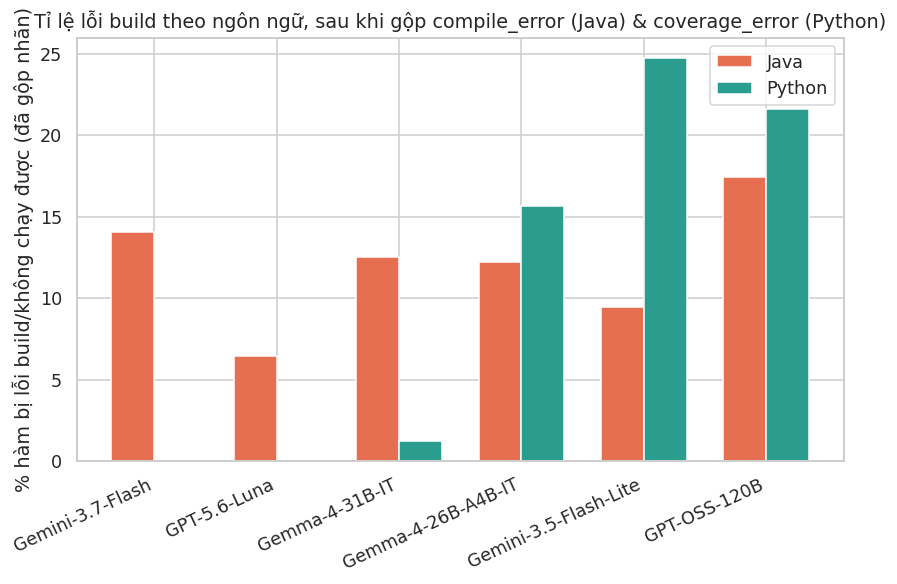

In [ ]:
build_err = df.groupby(['model', 'language'])['build_error'].mean().mul(100).unstack().loc[MODEL_ORDER]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(build_err)); width = 0.35
ax.bar(x - width/2, build_err['java'], width, label='Java', color=LANG_PALETTE['java'])
ax.bar(x + width/2, build_err['python'], width, label='Python', color=LANG_PALETTE['python'])
ax.set_xticks(x); ax.set_xticklabels(build_err.index, rotation=25, ha='right')
ax.set_ylabel('% hàm bị lỗi build/không chạy được (đã gộp nhãn)')
ax.set_title('Tỉ lệ lỗi build theo ngôn ngữ, sau khi gộp compile_error (Java) & coverage_error (Python)')
ax.legend()
save(fig, '09_build_error_rate')
plt.show()


### 5.9 Ma trận tương quan giữa các biến số

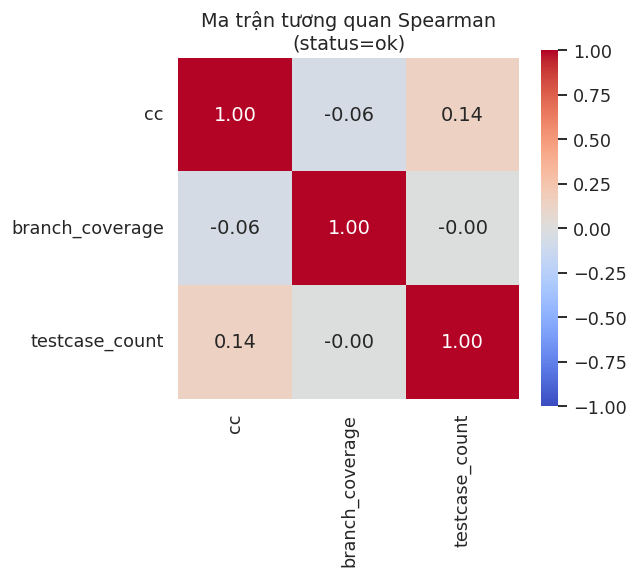

In [ ]:
corr_cols = ['cc', 'branch_coverage', 'testcase_count']
fig, ax = plt.subplots(figsize=(5, 4.2))
sns.heatmap(df_ok[corr_cols].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title('Ma trận tương quan Spearman\n(status=ok)')
save(fig, '10_correlation_heatmap')
plt.show()


<a id="6"></a>
## 6. Kiểm định thống kê

Biểu đồ cho trực giác, nhưng khi bảo vệ đồ án, giảng viên thường hỏi *"khác biệt đó có ý nghĩa thống kê không hay chỉ do ngẫu nhiên?"*. Mục này trả lời câu đó bằng các kiểm định phi tham số (vì `branch_coverage` không phân phối chuẩn — nó bị chặn trong [0, 100] và dồn nhiều ở gần 100%).


### 6.1 Kruskal-Wallis: 6 model có coverage trung bình khác nhau có ý nghĩa thống kê không?

In [ ]:
groups = [g['branch_coverage'].values for _, g in df_ok.groupby('model')]
h_stat, p_val = stats.kruskal(*groups)
print(f"Kruskal-Wallis H = {h_stat:.3f}, p-value = {p_val:.2e}")
print("=> " + ("Có khác biệt có ý nghĩa thống kê (p<0.05) giữa ít nhất 2 model." if p_val < 0.05
               else "KHÔNG đủ bằng chứng khác biệt giữa các model."))


Kruskal-Wallis H = 33.959, p-value = 2.43e-06
=> Có khác biệt có ý nghĩa thống kê (p<0.05) giữa ít nhất 2 model.


### 6.2 Kiểm định hậu kiểm (post-hoc) Mann-Whitney U theo từng cặp model, hiệu chỉnh Bonferroni

In [ ]:
models = MODEL_ORDER
pairs = list(itertools.combinations(models, 2))
alpha = 0.05
bonf_alpha = alpha / len(pairs)

rows = []
for a, b in pairs:
    ga = df_ok.loc[df_ok['model'] == a, 'branch_coverage']
    gb = df_ok.loc[df_ok['model'] == b, 'branch_coverage']
    u_stat, p = stats.mannwhitneyu(ga, gb, alternative='two-sided')
    rows.append({'Model A': a, 'Model B': b, 'Mean A': round(ga.mean(),1), 'Mean B': round(gb.mean(),1),
                 'p-value': p, 'Significant (Bonferroni)': p < bonf_alpha})

posthoc = pd.DataFrame(rows).sort_values('p-value')
print(f"Ngưỡng alpha sau hiệu chỉnh Bonferroni cho {len(pairs)} phép so sánh: {bonf_alpha:.5f}")
display(posthoc)


Ngưỡng alpha sau hiệu chỉnh Bonferroni cho 15 phép so sánh: 0.00333


,Model A,Model B,Mean A,Mean B,p-value,Significant (Bonferroni)
5,GPT-5.6-Luna,Gemma-4-31B-IT,86.4,95.8,1.230990e-07,True
6,GPT-5.6-Luna,Gemma-4-26B-A4B-IT,86.4,94.8,1.817262e-04,True
8,GPT-5.6-Luna,GPT-OSS-120B,86.4,94.5,4.007286e-04,True
0,Gemini-3.7-Flash,GPT-5.6-Luna,90.4,86.4,2.030625e-03,True
7,GPT-5.6-Luna,Gemini-3.5-Flash-Lite,86.4,94.4,4.654280e-03,False
10,Gemma-4-31B-IT,Gemini-3.5-Flash-Lite,95.8,94.4,1.161191e-02,False
1,Gemini-3.7-Flash,Gemma-4-31B-IT,90.4,95.8,1.734715e-02,False
9,Gemma-4-31B-IT,Gemma-4-26B-A4B-IT,95.8,94.8,1.622839e-01,False
14,Gemini-3.5-Flash-Lite,GPT-OSS-120B,94.4,94.5,1.944890e-01,False
12,Gemma-4-26B-A4B-IT,Gemini-3.5-Flash-Lite,94.8,94.4,2.758055e-01,False


### 6.3 Java vs Python: khác biệt coverage có ý nghĩa thống kê trong TỪNG model không?

In [ ]:
rows = []
for m in MODEL_ORDER:
    gj = df_ok.loc[(df_ok['model'] == m) & (df_ok['language'] == 'java'), 'branch_coverage']
    gp = df_ok.loc[(df_ok['model'] == m) & (df_ok['language'] == 'python'), 'branch_coverage']
    u, p = stats.mannwhitneyu(gj, gp, alternative='two-sided')
    rows.append({'Model': m, 'Java mean': round(gj.mean(), 1), 'Python mean': round(gp.mean(), 1),
                 'Chênh lệch': round(gp.mean() - gj.mean(), 1), 'p-value': p, 'Significant (p<0.05)': p < 0.05})

java_vs_py = pd.DataFrame(rows)
display(java_vs_py.style.background_gradient(subset=['Chênh lệch'], cmap='RdYlGn'))


,Model,Java mean,Python mean,Chênh lệch,p-value,Significant (p<0.05)
0,Gemini-3.7-Flash,83.300000,97.900000,14.600000,0.000000,True
1,GPT-5.6-Luna,81.100000,97.400000,16.300000,0.000000,True
2,Gemma-4-31B-IT,96.000000,95.500000,-0.600000,0.002279,True
3,Gemma-4-26B-A4B-IT,94.500000,95.300000,0.700000,0.001526,True
4,Gemini-3.5-Flash-Lite,94.000000,95.100000,1.200000,0.000587,True
5,GPT-OSS-120B,93.800000,95.300000,1.500000,0.001143,True


### 6.4 Chi-square: tỉ lệ các loại status có phụ thuộc vào model không?

In [ ]:
ct = pd.crosstab(df['model'], df['status'])
chi2, p, dof, expected = stats.chi2_contingency(ct)
n = ct.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
print(f"Chi-square = {chi2:.2f}, dof = {dof}, p-value = {p:.2e}")
print(f"Cramér's V (độ mạnh hiệu ứng) = {cramers_v:.3f}  "
      f"({'yếu' if cramers_v < 0.2 else 'trung bình' if cramers_v < 0.4 else 'mạnh'})")
print("=> Loại kết quả (ok/test_failed/compile_error/...) phụ thuộc có ý nghĩa thống kê vào model được dùng.")


Chi-square = 669.17, dof = 35, p-value = 2.72e-118
Cramér's V (độ mạnh hiệu ứng) = 0.186  (yếu)
=> Loại kết quả (ok/test_failed/compile_error/...) phụ thuộc có ý nghĩa thống kê vào model được dùng.


### 6.5 Tương quan Spearman giữa độ phức tạp (cc) và Branch Coverage

In [ ]:
rho, p = stats.spearmanr(df_ok['cc'], df_ok['branch_coverage'])
print(f"Toàn bộ dữ liệu:  rho = {rho:.3f}, p = {p:.2e}")
for lang in ['java', 'python']:
    sub = df_ok[df_ok['language'] == lang]
    rho, p = stats.spearmanr(sub['cc'], sub['branch_coverage'])
    print(f"{lang:8s}:       rho = {rho:.3f}, p = {p:.2e}")
print("\n(rho âm & có ý nghĩa thống kê => củng cố quan sát 'coverage cliff' ở mục 5.6:")
print(" hàm càng phức tạp, coverage trung bình càng giảm — dù mức độ tương quan có thể yếu)")


Toàn bộ dữ liệu:  rho = -0.061, p = 5.37e-03
java    :       rho = -0.089, p = 1.96e-03
python  :       rho = 0.029, p = 3.88e-01

(rho âm & có ý nghĩa thống kê => củng cố quan sát 'coverage cliff' ở mục 5.6:
 hàm càng phức tạp, coverage trung bình càng giảm — dù mức độ tương quan có thể yếu)


<a id="7"></a>
## 7. Phân tích sâu — các góc khai thác cho báo cáo

Dưới đây là những **hướng phân tích/insight cụ thể** nhóm có thể triển khai thêm và trình bày trước giảng viên — mỗi hướng đi kèm code khởi tạo để nhóm chạy thử và tự diễn giải theo số liệu thật.

**a) "Coverage cliff" theo độ phức tạp** *(đã làm ở 5.6/6.5)* — câu chuyện: model nào giữ được coverage ổn định nhất khi hàm phức tạp tăng dần? Model nào "sụp" mạnh nhất?

**b) Số lượng vs chất lượng test case** *(đã làm ở 5.7)* — model sinh nhiều test case nhất (`GPT-5.6-Luna`, `Gemini-3.7-Flash` theo bảng ở mục 4) có phải model có hiệu suất/test cao nhất không, hay có model sinh ít test nhưng "trúng" nhánh hơn?

**c) Bất đối xứng Java vs Python** *(đã làm ở 5.8, 6.3)* — model nào bị sụt coverage/tăng lỗi build rõ rệt khi chuyển từ Python sang Java? Đây thường là chỉ dấu model yếu về nắm cú pháp/type system tĩnh.

**d) "Ca khó chung" và "ca khó riêng"** — những hàm mà *toàn bộ* 6 model đều thất bại (khả năng cao là hàm thực sự khó, đáng đưa vào báo cáo làm case study định tính) vs những hàm mà mức độ thành công giữa các model chênh lệch rất lớn (cho thấy sự khác biệt năng lực thực sự, không phải do độ khó của hàm).

**e) Độ tin cậy của thực nghiệm** — dữ liệu hiện tại là **1 lần chạy duy nhất** cho mỗi (model, hàm). LLM có tính ngẫu nhiên (temperature > 0 thường), nên kết quả có thể dao động giữa các lần chạy. Nhóm nên nêu rõ đây là **giới hạn (limitation)** của nghiên cứu, và nếu còn thời gian, chạy lại một mẫu nhỏ (vd 20-30 hàm) nhiều lần để ước lượng phương sai.


In [ ]:
# (d) Case study: hàm khó chung cho tất cả model, và hàm gây chênh lệch lớn nhất giữa các model
pivot_cov = df.pivot_table(index='id', columns='model', values='branch_coverage', aggfunc='first')
pivot_cov['cc'] = df.drop_duplicates('id').set_index('id')['cc']
pivot_cov['language'] = df.drop_duplicates('id').set_index('id')['language']

pivot_cov['avg_coverage'] = pivot_cov[MODEL_ORDER].mean(axis=1)
pivot_cov['std_coverage'] = pivot_cov[MODEL_ORDER].std(axis=1)

print("=== Top 10 hàm KHÓ NHẤT (coverage trung bình thấp nhất trên cả 6 model) ===")
display(pivot_cov.sort_values('avg_coverage').head(10)[['language', 'cc', 'avg_coverage'] + MODEL_ORDER])

print("\n=== Top 10 hàm gây CHÊNH LỆCH lớn nhất giữa các model (độ lệch chuẩn cao) ===")
print("(đây là các hàm 'phân hóa' năng lực model rõ nhất — rất đáng đưa vào slide làm ví dụ minh họa)")
display(pivot_cov.sort_values('std_coverage', ascending=False).head(10)[['language', 'cc', 'avg_coverage', 'std_coverage'] + MODEL_ORDER])


=== Top 10 hàm KHÓ NHẤT (coverage trung bình thấp nhất trên cả 6 model) ===


model,language,cc,avg_coverage,Gemini-3.7-Flash,GPT-5.6-Luna,Gemma-4-31B-IT,Gemma-4-26B-A4B-IT,Gemini-3.5-Flash-Lite,GPT-OSS-120B
id,,,,,,,,,
java_final_0321,java,15,0.0,0.0,0.0,0.0,0.0,0.0,0.0
java_final_0305,java,14,0.0,0.0,0.0,0.0,0.0,0.0,0.0
java_final_0340,java,15,0.0,0.0,0.0,0.0,0.0,0.0,0.0
java_final_0356,java,15,0.0,0.0,0.0,0.0,0.0,0.0,0.0
java_final_0314,java,15,0.0,0.0,0.0,0.0,0.0,0.0,0.0
java_final_0280,java,11,0.0,0.0,0.0,0.0,0.0,0.0,0.0
java_final_0276,java,13,0.0,0.0,0.0,0.0,0.0,0.0,0.0
java_final_0279,java,12,0.0,0.0,0.0,0.0,0.0,0.0,0.0
java_final_0272,java,11,0.0,0.0,0.0,0.0,0.0,0.0,0.0



=== Top 10 hàm gây CHÊNH LỆCH lớn nhất giữa các model (độ lệch chuẩn cao) ===
(đây là các hàm 'phân hóa' năng lực model rõ nhất — rất đáng đưa vào slide làm ví dụ minh họa)


model,language,cc,avg_coverage,std_coverage,Gemini-3.7-Flash,GPT-5.6-Luna,Gemma-4-31B-IT,Gemma-4-26B-A4B-IT,Gemini-3.5-Flash-Lite,GPT-OSS-120B
id,,,,,,,,,,
py_final_0282,python,14,50.000000,54.772256,100.0,100.0,100.0,0.0,0.0,0.0
java_final_0032,java,7,50.000000,54.772256,100.0,100.0,0.0,0.0,100.0,0.0
py_final_0266,python,11,50.000000,54.772256,100.0,100.0,100.0,0.0,0.0,0.0
py_final_0128,python,10,50.000000,54.772256,100.0,100.0,100.0,0.0,0.0,0.0
py_final_0202,python,13,50.000000,54.772256,100.0,100.0,100.0,0.0,0.0,0.0
py_final_0222,python,12,50.000000,54.772256,100.0,100.0,100.0,0.0,0.0,0.0
py_final_0135,python,10,50.000000,54.772256,100.0,0.0,100.0,100.0,0.0,0.0
py_final_0253,python,11,49.166667,53.890321,100.0,100.0,95.0,0.0,0.0,0.0
py_final_0011,python,5,48.333333,53.072278,0.0,100.0,100.0,0.0,0.0,90.0


In [ ]:
# (b) Bảng xếp hạng hiệu suất test case đầy đủ, để trả lời "nhiều test có đồng nghĩa tốt?"
efficiency_table = df_ok.groupby('model').agg(
    Avg_Testcase=('testcase_count', 'mean'),
    Avg_Coverage=('branch_coverage', 'mean'),
    Avg_Efficiency=('coverage_efficiency', 'mean'),
).loc[MODEL_ORDER].round(2)
efficiency_table['Rank_by_Coverage'] = efficiency_table['Avg_Coverage'].rank(ascending=False).astype(int)
efficiency_table['Rank_by_Efficiency'] = efficiency_table['Avg_Efficiency'].rank(ascending=False).astype(int)
display(efficiency_table.sort_values('Avg_Coverage', ascending=False))
print("\nNếu Rank_by_Coverage và Rank_by_Efficiency lệch nhau nhiều ở model nào,")
print("=> model đó đang 'thắng' coverage một phần nhờ SỐ LƯỢNG test case, không hẳn nhờ chất lượng từng test.")


,Avg_Testcase,Avg_Coverage,Avg_Efficiency,Rank_by_Coverage,Rank_by_Efficiency
model,,,,,
Gemma-4-31B-IT,9.63,95.76,11.35,1,3
Gemma-4-26B-A4B-IT,9.72,94.85,10.74,2,4
GPT-OSS-120B,8.55,94.45,12.87,3,2
Gemini-3.5-Flash-Lite,7.61,94.41,15.26,4,1
Gemini-3.7-Flash,11.82,90.39,8.41,5,6
GPT-5.6-Luna,11.24,86.41,9.20,6,5



Nếu Rank_by_Coverage và Rank_by_Efficiency lệch nhau nhiều ở model nào,
=> model đó đang 'thắng' coverage một phần nhờ SỐ LƯỢNG test case, không hẳn nhờ chất lượng từng test.


<a id="8"></a>
## 8. Xuất bảng & biểu đồ

Toàn bộ biểu đồ đã được lưu vào thư mục `figures/` (định dạng PNG, 180dpi — đủ nét để chèn slide). Cell dưới đóng gói mọi thứ (bảng Excel tổng hợp + toàn bộ hình ảnh) thành 1 file zip để tải về máy.


In [29]:
with pd.ExcelWriter('bao_cao_tong_hop.xlsx', engine='openpyxl') as writer:
    summary_model.to_excel(writer, sheet_name='Summary_by_Model')
    summary_model_lang.to_excel(writer, sheet_name='Summary_by_Model_Language')
    cliff.to_excel(writer, sheet_name='Coverage_by_Complexity')
    posthoc.to_excel(writer, sheet_name='Posthoc_Model_Pairs', index=False)
    java_vs_py.to_excel(writer, sheet_name='Java_vs_Python', index=False)
    efficiency_table.to_excel(writer, sheet_name='Testcase_Efficiency')
    pivot_cov.sort_values('std_coverage', ascending=False).head(30).to_excel(writer, sheet_name='Top_Divergent_Functions')

import shutil
shutil.make_archive('bao_cao_ket_qua', 'zip', root_dir='.', base_dir='figures')

# gộp thêm file excel vào cùng 1 zip cho tiện
import zipfile
with zipfile.ZipFile('bao_cao_ket_qua.zip', 'a') as zf:
    zf.write('bao_cao_tong_hop.xlsx')

files.download('bao_cao_ket_qua.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<a id="9"></a>
## 9. Gợi ý outline trình bày báo cáo cho giảng viên

Một cấu trúc gợi ý (có thể điều chỉnh theo yêu cầu môn học), map trực tiếp tới các mục đã phân tích ở trên:

1. **Đặt vấn đề** — LLM sinh unit test tự động đang được quan tâm; câu hỏi nghiên cứu: *model nào sinh test bao phủ nhánh (branch coverage) tốt nhất, và điều gì ảnh hưởng tới chất lượng đó?*
2. **Thiết kế thực nghiệm**
   - Bộ dữ liệu: 646 hàm (327 Java, 319 Python), độ phức tạp cc phân bố cân bằng giữa 2 ngôn ngữ (→ biểu đồ mục 2).
   - Pipeline: sinh test bằng 6 LLM → biên dịch/chạy → đo branch coverage bằng JaCoCo/coverage.py.
   - Nêu rõ **giới hạn**: chạy 1 lần/hàm, nhãn lỗi build không đồng nhất giữa 2 ngôn ngữ (đã xử lý ở mục 3).
3. **Kết quả tổng quan** — bảng & biểu đồ Ok Rate, Avg Coverage theo model (mục 4, 5.1–5.3).
4. **Phân tích sâu**
   - Coverage cliff theo độ phức tạp (5.6).
   - Số lượng vs chất lượng test case (5.7, 7b).
   - Bất đối xứng Java/Python (5.8, 6.3).
   - Case study các hàm khó/phân hóa (7d).
5. **Kiểm định thống kê** — khẳng định các khác biệt quan sát được là có ý nghĩa thống kê, không phải nhiễu ngẫu nhiên (mục 6).
6. **Thảo luận & hạn chế** — dữ liệu 1 lần chạy, chưa kiểm soát temperature/prompt version giữa các model, chưa đo chi phí (token/tiền) để đánh giá đánh đổi hiệu năng-chi phí.
7. **Kết luận & hướng phát triển** — model nào nên dùng cho ngữ cảnh nào; đề xuất mở rộng (nhiều lần chạy để đo phương sai, thêm metric line coverage, thêm nhiều LLM/ngôn ngữ).

> 💡 Gợi ý khi thuyết trình: dùng bảng ở mục 4 làm slide "kết quả chính", chọn 3-4 biểu đồ ấn tượng nhất trong `figures/` (đề xuất: 02, 06, 07, 09) làm slide minh họa, và giữ mục kiểm định thống kê (mục 6) làm "vũ khí" trả lời câu hỏi phản biện của giảng viên.
